In [1]:
import pandas as pd

titanic_df=pd.read_csv("Datasets/train.csv")
test_df=pd.read_csv("Datasets/test.csv")
gender_df=pd.read_csv("Datasets/gender_submission.csv")

titanic_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
test_df.head()


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


ERROR! Session/line number was not unique in

 database. History logging moved to new session 11


In [3]:
gender_df.head()

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [4]:
titanic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Exercise 1: Duplicate Detection and Removal


In [5]:
titanic_df.duplicated().sum()

np.int64(0)

In [6]:
rows_before=len(titanic_df)
titanic_df_nodup=titanic_df.drop_duplicates()
rows_after=len(titanic_df_nodup)

print(f"Rows before: {rows_before}")
print(f"Rows after: {rows_after}")


Rows before: 891
Rows after: 891


Conclusion: no duplicates were found in the database

Exercise 2: Handling Missing Values

In [7]:
titanic_df_nodup.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
titanic_df_clean=titanic_df_nodup.dropna(subset=["Embarked"]).copy()
titanic_df_clean["Age"]=titanic_df_clean["Age"].fillna(titanic_df_clean["Age"].median())
titanic_df_clean["Cabin"]=titanic_df_clean["Cabin"].fillna("Unknown")

titanic_df_clean.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Conclusion: I found missing values in the Age, Cabin and Embarked columns. I filled the missing ages with the median, replaced missing Cabin values with "Unknown" and removed rows with missing Embarked values. After cleaning, there were no missing values left in the dataset.

Exercise 3: Feature Engineering

Instructions

Create new features, such as Family Size from SibSp and Parch, and Title extracted from the Name column.
Convert categorical variables into numerical form using techniques like one-hot encoding or label encoding.
You will encode new categorical features (like Title) here, but do not scale numerical features yet — that will come after outlier handling.

In [9]:
titanic_df_clean.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [10]:
titanic_df_clean["FamilySize"]=titanic_df_clean["SibSp"]+titanic_df_clean["Parch"]+1
titanic_df_clean["Title"]= (
    titanic_df_clean["Name"]
    .str.split(",").str[1]
    .str.split(".").str[0]
    .str.strip()
)
titanic_df_clean.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S,2,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,1,Mr


In [11]:
title_encoded = pd.get_dummies(
    titanic_df_clean["Title"],
    prefix="Title",
    dtype=int
)

title_encoded.head()

,Title_Capt,Title_Col,Title_Don,Title_Dr,Title_Jonkheer,Title_Lady,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [12]:
titanic_df_clean = titanic_df_clean.join(title_encoded)

titanic_df_clean.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,0,0,0,0,1,0,0,0,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,0,0,0,0,0,1,0,0,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,0,1,0,0,0,0,0,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,0,0,0,0,0,1,0,0,0,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,0,0,0,0,1,0,0,0,0,0


In [14]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 1.1 MB/s  0:00:09m0:00:0100:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.2 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


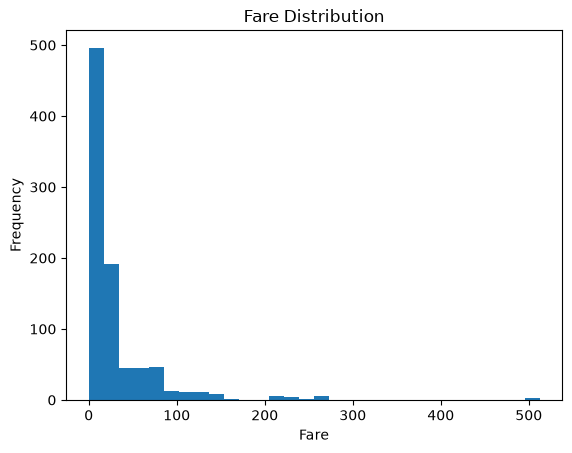

In [15]:
import matplotlib.pyplot as plt

plt.hist(titanic_df_clean["Fare"], bins=30)
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

In [22]:
q1_fare=titanic_df_clean["Fare"].quantile(0.25)
q3_fare=titanic_df_clean["Fare"].quantile(0.75)
iqr_fare=q3_fare - q1_fare
low_fare=q1_fare-1.5*iqr_fare
high_fare=q3_fare+1.5*iqr_fare
fare_outliers=titanic_df_clean[
    ~titanic_df_clean["Fare"].between(low_fare,high_fare)
    ]

display(low_fare)
display(high_fare)

display(fare_outliers)

np.float64(-26.7605)

np.float64(65.6563)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,0,0,0,0,0,1,0,0,0,0
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,...,0,0,0,0,1,0,0,0,0,0
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,28.0,1,0,PC 17569,146.5208,...,0,0,0,0,0,1,0,0,0,0
34,35,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,...,0,0,0,0,1,0,0,0,0,0
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
846,847,0,3,"Sage, Mr. Douglas Bullen",male,28.0,8,2,CA. 2343,69.5500,...,0,0,0,0,1,0,0,0,0,0
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,28.0,1,0,17453,89.1042,...,0,0,0,0,0,1,0,0,0,0
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,...,0,0,0,0,0,1,0,0,0,0
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,28.0,8,2,CA. 2343,69.5500,...,0,1,0,0,0,0,0,0,0,0


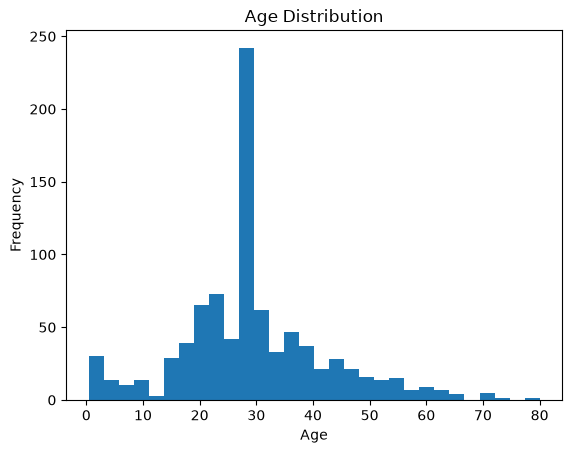

In [17]:
plt.hist(titanic_df_clean["Age"], bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

In [35]:
q1_age=titanic_df_clean["Age"].quantile(0.25)
q3_age=titanic_df_clean["Age"].quantile(0.75)
iqr_age=q3_age - q1_age
low_age=q1_age-1.5*iqr_age
high_age=q3_age+1.5*iqr_age
age_outliers=titanic_df_clean[
    ~titanic_df_clean["Age"].between(low_age,high_age)
    ]

display("Lower boundary:", low_age)
display("Upper boundary:", high_age)
display("Outliers:", age_outliers.shape[0])

'Lower boundary:'

np.float64(2.5)

'Upper boundary:'

np.float64(54.5)

'Outliers:'

65

In [28]:
fare_cap = titanic_df_clean["Fare"].quantile(0.98)

titanic_df_clean["Fare_capped"] = (
    titanic_df_clean["Fare"].clip(upper=fare_cap)
)

titanic_df_clean[["Fare", "Fare_capped"]].describe()

,Fare,Fare_capped
count,889.000000,889.000000
mean,32.096681,30.567524
std,49.697504,39.881074
min,0.000000,0.000000
25%,7.895800,7.895800
50%,14.454200,14.454200
75%,31.000000,31.000000
max,512.329200,211.337500


In [29]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [32]:
import numpy as np

titanic_df_clean["Fare_logged"]=np.log1p(titanic_df_clean["Fare"])

titanic_df_clean[["Fare","Fare_capped","Fare_logged"]].describe()

,Fare,Fare_capped,Fare_logged
count,889.000000,889.000000,889.000000
mean,32.096681,30.567524,2.959024
std,49.697504,39.881074,0.967750
min,0.000000,0.000000,0.000000
25%,7.895800,7.895800,2.185579
50%,14.454200,14.454200,2.737881
75%,31.000000,31.000000,3.465736
max,512.329200,211.337500,6.240917


In [33]:
titanic_df_clean[["Fare", "Fare_capped", "Fare_logged"]].skew()

Fare           4.801440
Fare_capped    2.814448
Fare_logged    0.400109
dtype: float64

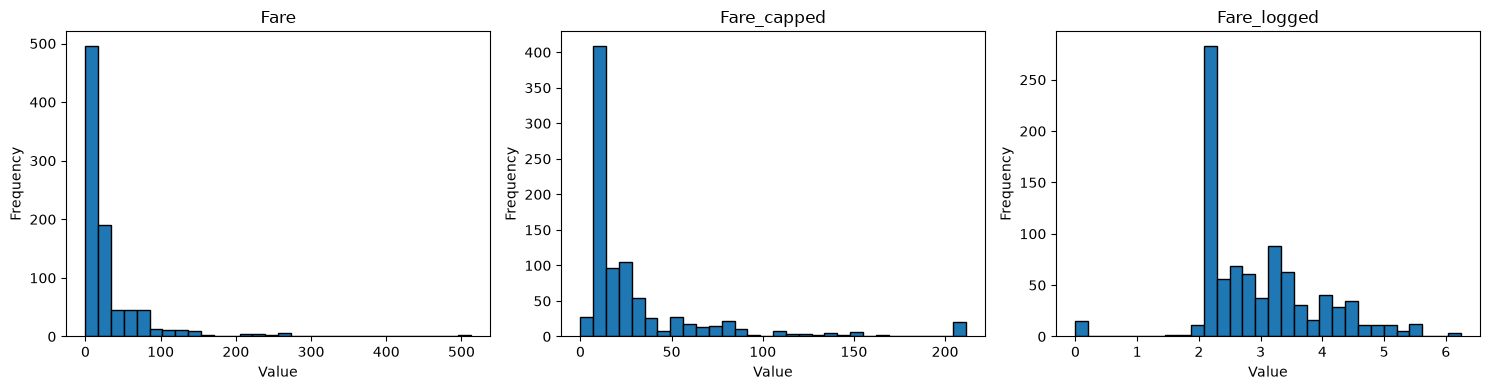

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

columns = ["Fare", "Fare_capped", "Fare_logged"]

for ax, column in zip(axes, columns):
    ax.hist(titanic_df_clean[column], bins=30, edgecolor="black")
    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

I used the IQR method to detect outliers in the Fare and Age columns.

Fare: 114 potential outliers were detected.

Age: 65 potential outliers were detected.

For Fare, I applied two methods: quantile capping at the 98th percentile and logarithmic transformation. Capping reduced the maximum fare from 512.33 to 211.34, while logarithmic transformation compressed the range of values.

I decided to keep the original Age values because very young and older passengers represent realistic ages, not necessarily data errors.

Both transformations were saved in separate columns to allow comparison with the original data.

Exercise 5: Data Standardization and Normalization

Goal: Scale numerical features to prepare for modeling.

Use StandardScaler (mean = 0, std = 1) for normally distributed features.
Use MinMaxScaler (range [0, 1]) for features that are skewed or bounded.


In [39]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 890.6 kB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 4.0 MB/s  0:00:05 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [40]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler


standard_scaler = StandardScaler()

titanic_df_clean["Age_standardized"] = standard_scaler.fit_transform(
    titanic_df_clean[["Age"]]
).ravel()


minmax_scaler = MinMaxScaler()

titanic_df_clean["Fare_normalized"] = minmax_scaler.fit_transform(
    titanic_df_clean[["Fare_capped"]]
).ravel()

In [41]:
titanic_df_clean[
    ["Age", "Age_standardized", "Fare_capped", "Fare_normalized"]
].describe()

,Age,Age_standardized,Fare_capped,Fare_normalized
count,889.000000,8.890000e+02,889.000000,889.000000
mean,29.315152,2.717486e-16,30.567524,0.144638
std,12.984932,1.000563e+00,39.881074,0.188708
min,0.420000,-2.226536e+00,0.000000,0.000000
25%,22.000000,-5.636741e-01,7.895800,0.037361
50%,28.000000,-1.013399e-01,14.454200,0.068394
75%,35.000000,4.380499e-01,31.000000,0.146685
max,80.000000,3.905556e+00,211.337500,1.000000


I used StandardScaler to standardize the Age column and MinMaxScaler to normalize the capped Fare values.

After standardization, Age has a mean close to 0 and a standard deviation close to 1.

After normalization, Fare values are between 0 and 1.

I saved the scaled values in new columns to keep the original data for comparison.

Exercise 6: Feature Encoding

Goal: Finalize categorical variable encoding.

1. Identify remaining categorical columns (e.g. Sex, Embarked, Title).
2. Apply:

One-Hot Encoding for nominal variables.
Label Encoding if any ordinal variables remain.
3. Merge encoded columns back into the main dataset.



In [42]:
categorical_encoded = pd.get_dummies(
    titanic_df_clean[["Sex", "Embarked"]],
    dtype=int
)

titanic_df_clean = titanic_df_clean.join(categorical_encoded)

titanic_df_clean[
    ["Sex", "Embarked", "Sex_female", "Sex_male",
     "Embarked_C", "Embarked_Q", "Embarked_S"]
].head()

,Sex,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,male,S,0,1,0,0,1
1,female,C,1,0,1,0,0
2,female,S,1,0,0,0,1
3,female,S,1,0,0,0,1
4,male,S,0,1,0,0,1


I used One-Hot Encoding to convert the Sex and Embarked columns into numerical features.

The Title column was already encoded in Exercise 3, so I did not encode it again.

I joined the new columns to the existing DataFrame and kept the original categorical columns for comparison.

Exercise 7: Data Transformation for Age Feature

Goal: Create and encode age groups.

Use pd.cut() to create bins for life stages (e.g. child, teen, adult, senior).
Apply one-hot encoding using pd.get_dummies().

In [43]:
age_bins = [0, 12, 18, 60, 100]
age_labels = ["Child", "Teenager", "Adult", "Senior"]

titanic_df_clean["AgeGroup"] = pd.cut(
    titanic_df_clean["Age"],
    bins=age_bins,
    labels=age_labels
)

In [44]:
age_encoded = pd.get_dummies(
    titanic_df_clean["AgeGroup"],
    prefix="AgeGroup",
    dtype=int
)

titanic_df_clean = titanic_df_clean.join(age_encoded)

In [45]:
titanic_df_clean[
    ["Age", "AgeGroup", "AgeGroup_Child",
     "AgeGroup_Teenager", "AgeGroup_Adult", "AgeGroup_Senior"]
].head(10)

,Age,AgeGroup,AgeGroup_Child,AgeGroup_Teenager,AgeGroup_Adult,AgeGroup_Senior
0,22.0,Adult,0,0,1,0
1,38.0,Adult,0,0,1,0
2,26.0,Adult,0,0,1,0
3,35.0,Adult,0,0,1,0
4,35.0,Adult,0,0,1,0
5,28.0,Adult,0,0,1,0
6,54.0,Adult,0,0,1,0
7,2.0,Child,1,0,0,0
8,27.0,Adult,0,0,1,0
9,14.0,Teenager,0,1,0,0


In [46]:
titanic_df_clean["AgeGroup"].value_counts()

AgeGroup
Adult       729
Teenager     70
Child        69
Senior       21
Name: count, dtype: int64

I used pd.cut() to divide passengers into four age groups: Child, Teenager, Adult, and Senior.

Then I applied One-Hot Encoding to convert the age groups into numerical columns and joined them to the DataFrame.

The original Age column was kept for comparison.